### This notebook is going to perform an EDA of the PEM large dataset

In [1]:
# Import relevant modules
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler

from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import SelectFromModel
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import numpy as np
from scipy.stats import randint, uniform, loguniform
import joblib
import xgboost as xgb

In [2]:
# import pem dataset
pem = pd.read_csv('../data/pem_electrolyser_dataset.csv', encoding='ISO-8859-1')

In [3]:
pem.head()

,electrolysis_type,Anode_type,Cathode_type,Anode_GDE,Cathode_GDE,electrode_area(cm2),cathode_flow_area(cm2),anode_flow_area(cm2),membrane_type,cathode_catalyst,...,Cell_current_des(A/cm2),power(w),power(W/cm2),water_flow_rate(ml/min),Hydrogen_flow_rate,Temprature_cell(k),Pressuer(atm),Electrode_shape,Flow_type_A (Number),Flow_type_C (Number)
0,PEM,carbon_plate,carbon_plate,porous_carbon_paper,porous_carbon_paper,9.0,5.85,5.85,nafion117,MoS2,...,0.006964,0.110002,0.018804,6,0.100,293.15,1.0,rectangular,1,1
1,PEM,carbon_plate,carbon_plate,porous_carbon_paper,porous_carbon_paper,9.0,5.85,5.85,nafion117,MoS2,...,0.014786,0.259501,0.044359,6,0.675,293.15,1.0,rectangular,1,1
2,PEM,carbon_plate,carbon_plate,porous_carbon_paper,porous_carbon_paper,9.0,5.85,5.85,nafion117,MoS2,...,0.026414,0.509915,0.087165,6,1.100,293.15,1.0,rectangular,1,1
3,PEM,carbon_plate,carbon_plate,porous_carbon_paper,porous_carbon_paper,9.0,5.85,5.85,nafion117,MoS2,...,0.043238,0.910592,0.155657,6,1.900,293.15,1.0,rectangular,1,1
4,PEM,carbon_plate,carbon_plate,porous_carbon_paper,porous_carbon_paper,9.0,5.85,5.85,nafion117,MoS2,...,0.064428,1.469932,0.251270,6,3.000,293.15,1.0,rectangular,1,1


In [4]:
# rename columns and set all to lowercase for consistency
pem.columns = pem.columns.str.lower().str.replace(' ', '_').str.replace('(', '').str.replace(')', '')

In [5]:
for col in pem.select_dtypes(include='object').columns: #assign category type to categorical features
    pem[col] = pem[col].astype('category')
    
#remove cell_design_type
pem.drop('cell_design_type', axis=1, inplace=True)
pem.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1062 entries, 0 to 1061
Data columns (total 25 columns):
 #   Column                 Non-Null Count  Dtype   
---  ------                 --------------  -----   
 0   electrolysis_type      1062 non-null   category
 1   anode_type             1062 non-null   category
 2   cathode_type           1062 non-null   category
 3   anode_gde              1062 non-null   category
 4   cathode_gde            1062 non-null   category
 5   electrode_areacm2      1062 non-null   float64 
 6   cathode_flow_areacm2   1062 non-null   float64 
 7   anode_flow_areacm2     1062 non-null   float64 
 8   membrane_type          1062 non-null   category
 9   cathode_catalyst       1062 non-null   category
 10  anode_catalyst         1062 non-null   category
 11  catholyte              1062 non-null   category
 12  anolyte                1062 non-null   category
 13  cell_design_number     1062 non-null   int64   
 14  cell_voltage           1062 non-null   f

In [6]:
# Change flow_type to categorical as well
pem['flow_type_a_number'] = pem['flow_type_a_number'].astype('category')
pem['flow_type_c_number'] = pem['flow_type_c_number'].astype('category')

In [7]:
for columns in pem.columns:
    if pem[columns].dtype == 'category':
        print(f"Value counts for {columns}:\n{pem[columns].value_counts()}\n")

Value counts for electrolysis_type:
electrolysis_type
PEM    1062
Name: count, dtype: int64

Value counts for anode_type:
anode_type
Titanium                                                            539
carbon_plate                                                        334
316L_stainless_steel_felt316L_stainless_steel_felt                   77
316L_stainless_steel_felt317L_stainless_steel_felt                   76
silver_coated_3D_printed_components_fabricate_from_polypropylene     30
Ni_foam                                                               6
Name: count, dtype: int64

Value counts for cathode_type:
cathode_type
carbon_plate                                                        508
Titanium                                                            371
316L_stainless_steel_felt316L_stainless_steel_felt                   77
316L_stainless_steel_felt317L_stainless_steel_felt                   76
silver_coated_3D_printed_components_fabricate_from_polypropylene     30
Name

In [8]:
print(pem.describe()) # describe dataset

       electrode_areacm2  cathode_flow_areacm2  anode_flow_areacm2  \
count        1062.000000           1062.000000         1062.000000   
mean           40.123164             17.957166           18.411704   
std            30.584177             15.992257           15.678287   
min             9.000000              4.000000            4.000000   
25%            16.000000              5.720000            6.150000   
50%            25.000000              7.840000            9.000000   
75%            64.000000             25.000000           25.000000   
max           100.000000             50.000000           50.000000   

       cell_design_number  cell_voltage  cell_current_desa/cm2       powerw  \
count         1062.000000   1062.000000            1062.000000  1062.000000   
mean             1.951977      3.558102               0.496972    63.101260   
std              2.466849      4.162981               0.492780   152.263523   
min              1.000000      1.380000              

Make **boxplots of current density against**, membrane types, Anode types, cathode types, Anode Catalysts, cathode catalysts, GDEs, anolytes and catholytes

C:\ProgramData\Anaconda3\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 153 (\x99) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


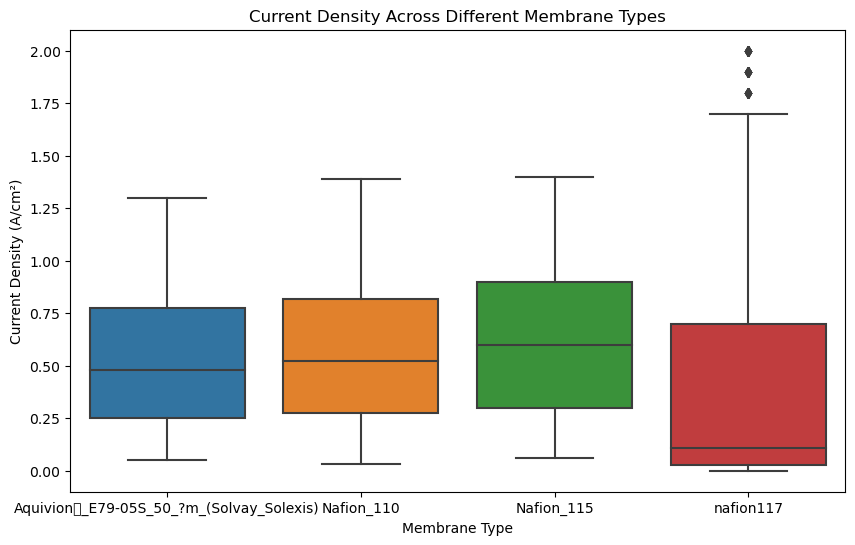

In [9]:
#Membrane types
plt.figure(figsize=(10, 6))
sns.boxplot(x='membrane_type', y='cell_current_desa/cm2', data=pem)
plt.xlabel('Membrane Type')
plt.ylabel('Current Density (A/cm²)')
plt.title('Current Density Across Different Membrane Types')
plt.show()
plt.close()

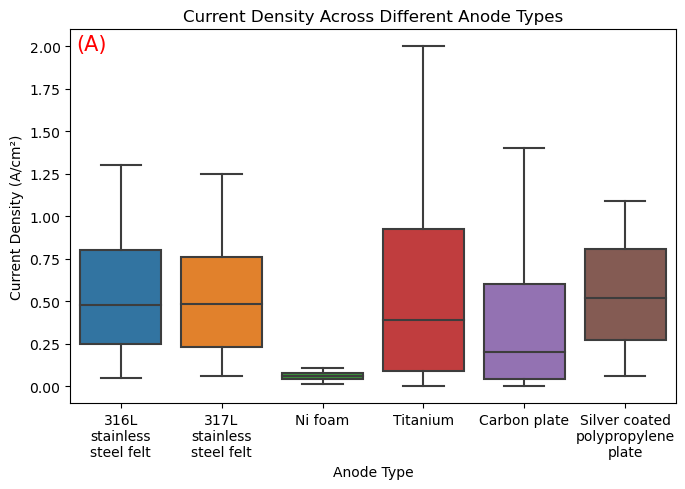

In [46]:
#Anode Types
plt.figure(figsize=(7, 5))
anode_type = sns.boxplot(x='anode_type', y='cell_current_desa/cm2', data=pem)
plt.xlabel('Anode Type')

plt.ylabel('Current Density (A/cm²)')
plt.title('Current Density Across Different Anode Types')
#get labels
labels = [label.get_text() for label in anode_type.get_xticklabels()]
# replace _ for newline
new_labels = [label.replace('_', '\n') for label in labels]

custom_labels = ['316L\nstainless\nsteel felt', '317L\nstainless\nsteel felt', 'Ni foam', 'Titanium', 'Carbon plate', 'Silver coated\npolypropylene\nplate']

plt.text(0.01,0.96, '(A)', fontsize=15, color='red', 
         verticalalignment='center', horizontalalignment='left',
         transform=plt.gca().transAxes,  
         )




# Set the new labels
anode_type.set_xticklabels(custom_labels)

plt.subplots_adjust(bottom=0.2)
plt.tight_layout()
plt.show()
plt.close()

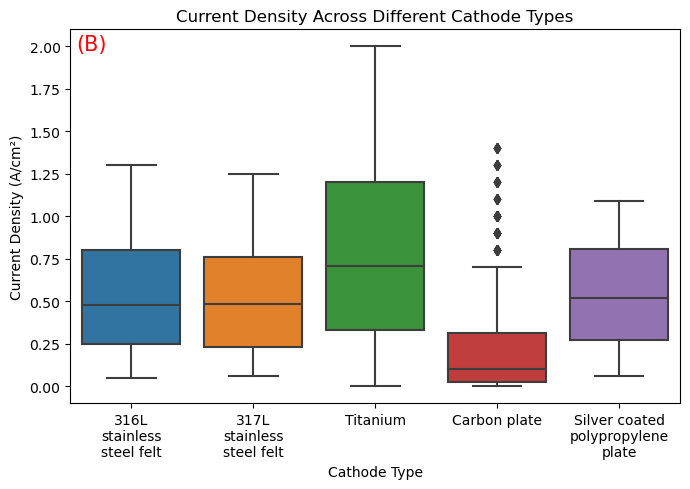

In [57]:
#Cathode_types
plt.figure(figsize=(7, 5))
graph = sns.boxplot(x='cathode_type', y='cell_current_desa/cm2', data=pem)
plt.xlabel('Cathode Type')

plt.ylabel('Current Density (A/cm²)')
plt.title('Current Density Across Different Cathode Types')
#get labels
labels = [label.get_text() for label in graph.get_xticklabels()]
# replace _ for newline
new_labels = [label.replace('_', '\n') for label in labels]
custom_labels = ['316L\nstainless\nsteel felt', '317L\nstainless\nsteel felt', 'Titanium', 'Carbon plate', 'Silver coated\npolypropylene\nplate']

plt.text(0.01,0.96, '(B)', fontsize=15, color='red', 
         verticalalignment='center', horizontalalignment='left',
         transform=plt.gca().transAxes,  
         )




# Set the new labels
graph.set_xticklabels(custom_labels)

plt.subplots_adjust(bottom=0.2)
plt.tight_layout()
plt.show()
plt.close()

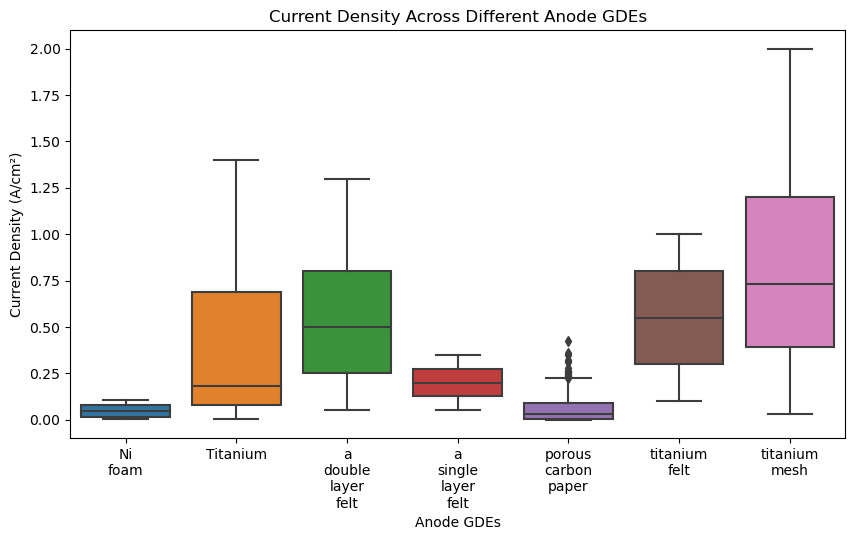

In [12]:
#Anode GDE
plt.figure(figsize=(10, 6))
graph = sns.boxplot(x='anode_gde', y='cell_current_desa/cm2', data=pem)
plt.xlabel('Anode GDEs')

plt.ylabel('Current Density (A/cm²)')
plt.title('Current Density Across Different Anode GDEs')
#get labels
labels = [label.get_text() for label in graph.get_xticklabels()]
# replace _ for newline
new_labels = [label.replace('_', '\n') for label in labels]

# Set the new labels
graph.set_xticklabels(new_labels)

plt.subplots_adjust(bottom=0.2)
plt.show()
plt.close()

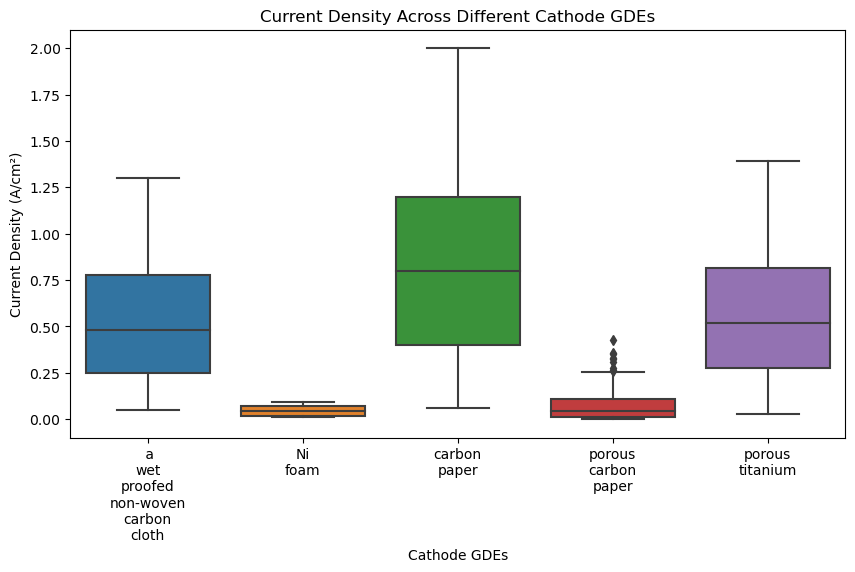

In [13]:
#Cahode GDE
plt.figure(figsize=(10, 6))
graph = sns.boxplot(x='cathode_gde', y='cell_current_desa/cm2', data=pem)
plt.xlabel('Cathode GDEs')

plt.ylabel('Current Density (A/cm²)')
plt.title('Current Density Across Different Cathode GDEs')
#get labels
labels = [label.get_text() for label in graph.get_xticklabels()]
# replace _ for newline
new_labels = [label.replace('_', '\n') for label in labels]

# Set the new labels
graph.set_xticklabels(new_labels)

plt.subplots_adjust(bottom=0.2)
plt.show()
plt.close()

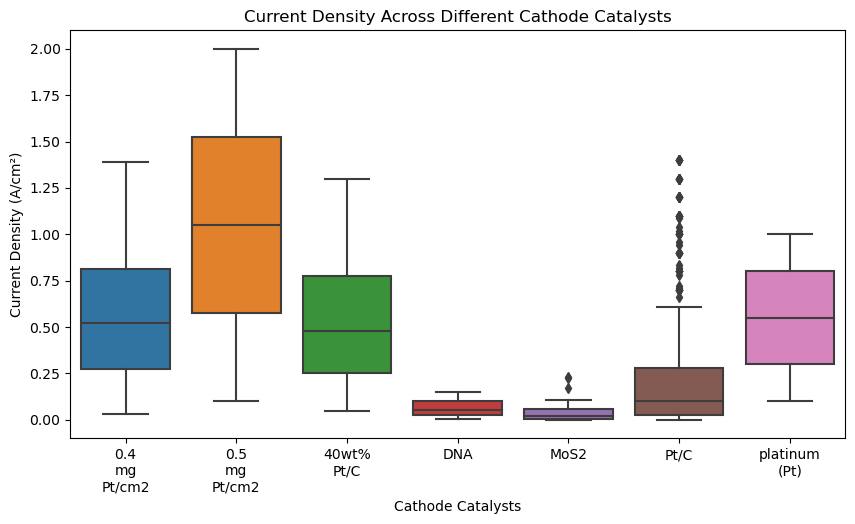

In [14]:
#cathode_catalyst
plt.figure(figsize=(10, 6))
graph = sns.boxplot(x='cathode_catalyst', y='cell_current_desa/cm2', data=pem)
plt.xlabel('Cathode Catalysts')

plt.ylabel('Current Density (A/cm²)')
plt.title('Current Density Across Different Cathode Catalysts')
#get labels
labels = [label.get_text() for label in graph.get_xticklabels()]
# replace _ for newline
new_labels = [label.replace('_', '\n') for label in labels]

# Set the new labels
graph.set_xticklabels(new_labels)

plt.subplots_adjust(bottom=0.2)
plt.show()
plt.close()

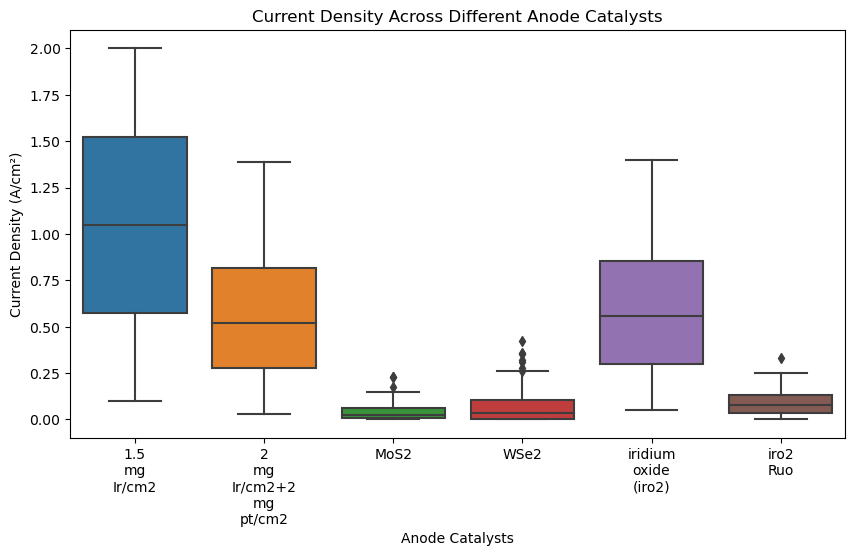

In [15]:
#Anode catalyst
plt.figure(figsize=(10, 6))
graph = sns.boxplot(x='anode_catalyst', y='cell_current_desa/cm2', data=pem)
plt.xlabel('Anode Catalysts')

plt.ylabel('Current Density (A/cm²)')
plt.title('Current Density Across Different Anode Catalysts')
#get labels
labels = [label.get_text() for label in graph.get_xticklabels()]
# replace _ for newline
new_labels = [label.replace('_', '\n') for label in labels]

# Set the new labels
graph.set_xticklabels(new_labels)

plt.subplots_adjust(bottom=0.2)
plt.show()
plt.close()

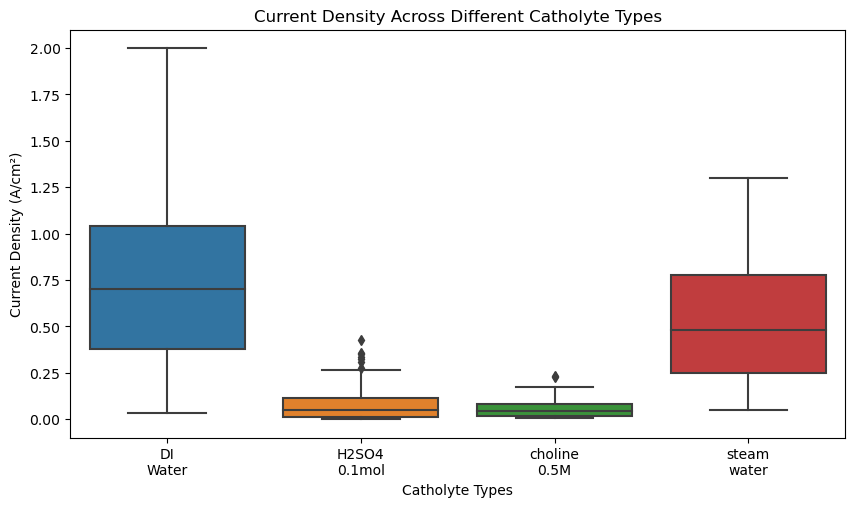

In [16]:
#catholytes
plt.figure(figsize=(10, 6))
graph = sns.boxplot(x='catholyte', y='cell_current_desa/cm2', data=pem)
plt.xlabel('Catholyte Types')

plt.ylabel('Current Density (A/cm²)')
plt.title('Current Density Across Different Catholyte Types')
#get labels
labels = [label.get_text() for label in graph.get_xticklabels()]
# replace _ for newline
new_labels = [label.replace('_', '\n') for label in labels]

# Set the new labels
graph.set_xticklabels(new_labels)

plt.subplots_adjust(bottom=0.2)
plt.show()
plt.close()

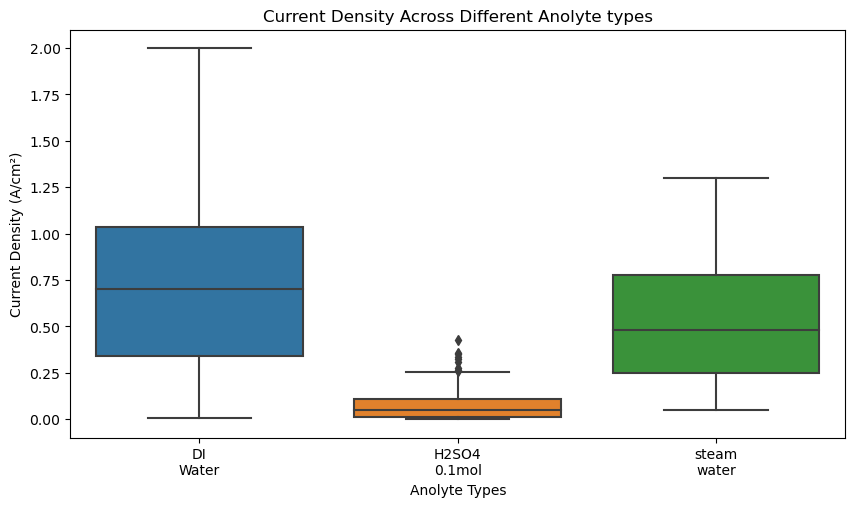

In [17]:
#Anolyte types
plt.figure(figsize=(10, 6))
graph = sns.boxplot(x='anolyte', y='cell_current_desa/cm2', data=pem)
plt.xlabel('Anolyte Types')

plt.ylabel('Current Density (A/cm²)')
plt.title('Current Density Across Different Anolyte types')
#get labels
labels = [label.get_text() for label in graph.get_xticklabels()]
# replace _ for newline
new_labels = [label.replace('_', '\n') for label in labels]

# Set the new labels
graph.set_xticklabels(new_labels)

plt.subplots_adjust(bottom=0.2)
plt.show()
plt.close()

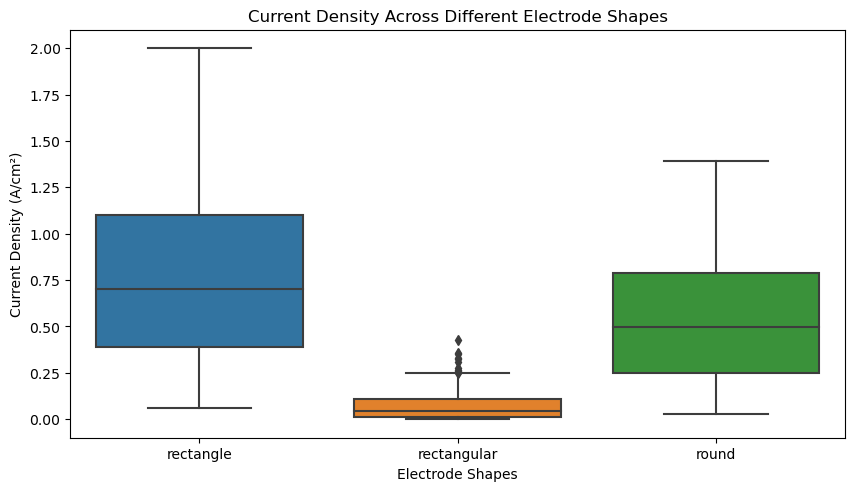

In [18]:
#electrode_shape
plt.figure(figsize=(10, 6))
graph = sns.boxplot(x='electrode_shape', y='cell_current_desa/cm2', data=pem)
plt.xlabel('Electrode Shapes')

plt.ylabel('Current Density (A/cm²)')
plt.title('Current Density Across Different Electrode Shapes')
#get labels
labels = [label.get_text() for label in graph.get_xticklabels()]
# replace _ for newline
new_labels = [label.replace('_', '\n') for label in labels]

# Set the new labels
graph.set_xticklabels(new_labels)

plt.subplots_adjust(bottom=0.2)
plt.show()
plt.close()

### Power against hydrogen flow rate

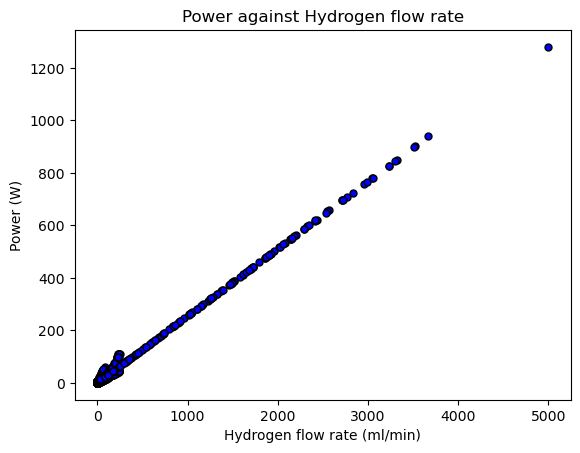

<Figure size 640x480 with 0 Axes>

In [30]:
plt.scatter(pem['hydrogen_flow_rate'], pem['powerw'], marker='o', color='blue', edgecolors='black', s=25)
plt.xlabel('Hydrogen flow rate (ml/min)')
plt.ylabel('Power (W)')
plt.title('Power against Hydrogen flow rate')
plt.show()
plt.clf()